# Contact List Merge: a step-by-step walkthrough

Six messy lead exports go in, one clean contact list comes out. This notebook walks through every stage of the pipeline
on a small **synthetic** sample (37 rows, all invented), showing the data before and after each step and *why* each rule
exists.

It imports the real, tested code from `pipeline/` rather than re-implementing it, so what you see here is what the tests
and the n8n workflow are checked against.

| Step | What happens | Section |
|---|---|---|
| 0 | Look at the raw exports | [Raw data](#0.-The-raw-data) |
| 1 | Map six schemas onto one record shape | [Map columns](#1.-Map-columns-to-one-record-shape) |
| 2 | Clean fields, remove invalid rows | [Clean + validate](#2.-Clean-and-remove-invalid-records) |
| 3 | Standardize to the Rules-tab formats | [Standardize](#3.-Standardize-to-the-Rules-tab-formats) |
| 4 | Find which records are the same person | [Group people](#4.-Group-records-into-people) |
| 5 | Enrich gaps and merge each group | [Merge](#5.-Enrich-and-merge-one-row-per-person) |
| 6 | Verify against the golden file and the n8n code | [Verify](#6.-Verify) |

**Run it:** `pip install -r requirements.txt -r requirements-notebook.txt`, then open this file with Jupyter from the
`notebooks/` folder. Node is only needed for the optional parity cell at the end.

In [1]:
%matplotlib inline
import dataclasses
import re
import shutil
import subprocess
import sys
from collections import Counter
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT))

from pipeline.build import COLUMNS, build_all
from pipeline.cluster import _strong_keys, build_clusters, prepare
from pipeline.loaders import load_all
from pipeline.run import DATA

pd.set_option("display.max_colwidth", 48)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BLUE, ORANGE, GREEN, RED, GREY, AMBER = "#3b82f6", "#c2410c", "#047857", "#dc2626", "#64748b", "#b45309"
print("data folder:", DATA.relative_to(ROOT))

data folder: sample-data


## 0. The raw data

Each source is an Excel export with its own column names, date formats and quirks. Here are the Google Ads form and
the conference delegate list (which has banner rows above its header and a footer row below the data).

In [2]:
raw = {
    "Google Ads": pd.read_excel(DATA / "01_GoogleAds_LeadForm_Export.xlsx"),
    "Event delegates": pd.read_excel(DATA / "02_Event_Delegates_and_Scans.xlsx", sheet_name="Delegate List", header=4),
    "Event scans": pd.read_excel(DATA / "02_Event_Delegates_and_Scans.xlsx", sheet_name="Booth Scans"),
    "LinkedIn form": pd.read_excel(DATA / "03_LinkedIn_LeadGenForm_Export.xlsx"),
    "Scraped LinkedIn": pd.read_excel(DATA / "04_LinkedIn_Scraped_SalesNav.xlsx"),
    "Apollo": pd.read_excel(DATA / "05_ThirdParty_Apollo_Export.xlsx"),
    "ZoomInfo": pd.read_excel(DATA / "06_ThirdParty_ZoomInfo_Export.xlsx"),
}
# the delegate sheet has a blank row and a "Total Delegates" footer: keep only real rows (those with a serial number)
raw["Event delegates"] = raw["Event delegates"][raw["Event delegates"]["S.No"].notna()]
print({name: len(df) for name, df in raw.items()}, "-> total", sum(len(df) for df in raw.values()))
raw["Google Ads"][["Full name", "Work email", "Phone number", "Company name", "Job title"]]

{'Google Ads': 8, 'Event delegates': 4, 'Event scans': 2, 'LinkedIn form': 4, 'Scraped LinkedIn': 7, 'Apollo': 8, 'ZoomInfo': 4} -> total 37


,Full name,Work email,Phone number,Company name,Job title
0,LENA PARK,lena.park@kestrellogistics.com,98000 10001,Kestrel Logistics Pvt Ltd,Mktg Manager
1,omar diaz,omardiaz7731x@gmail.com,09700020001,Kestrel,Dir. Sales
2,Tom Baker,tom.baker@lumenretail.con,NaN,Lumen Retial,Head of IT
3,Nina Cho,nina.cho@sparrowfin.io; info@sparrowfin.io,0000000000,Sparrow Fintech Pte. Ltd.,Sr Mgr - Sales
4,Nina Cho,nina.cho@sparrowfin.io; info@sparrowfin.io,0000000000,Sparrow Fintech Pte. Ltd.,Sr Mgr - Sales
5,Google Test,lead-test@google-test.invalid,0000000000,Google Test Co,QA
6,Alex Student,alexstudent@gmail.com,NaN,Student,Looking for job
7,asdf asdf,asdf@asdf.invalid,1234567890,asdf,asdf


In [3]:
raw["Event delegates"][["S.No", "Name of Delegate", "Organisation", "Designation", "Contact No", "Email ID"]]

,S.No,Name of Delegate,Organisation,Designation,Contact No,Email ID
0,1.0,"PARK, LENA",Kestrel,Chief Rev Officer,9800010002,lpark@kestrellogistics.com
1,2.0,Mr. Maya Iyer,Driftwood Pay Pte. Ltd.,Growth Head,+6590001234,maya.iyer@driftwoodpay.com
2,3.0,ravi menon,NaN,Manager - Procurement,9.18772E+11,ravi.menon@sparrowfin.io
3,4.0,Sam Ortiz,Harbor,Purchase Manager,080-43057296,mailto:sam.ortiz@harborsoft.com


Things to notice: ALL-CAPS names, `Last, First` ordering, a blank organisation, e-mails padded with spaces or prefixed
`mailto:`, a number mangled by Excel into scientific notation (`9.18772E+11`), a landline (`080-...`), and a footer row.
The pipeline has a rule for each of these ([full catalogue](../docs/data-quality-catalogue.md)).

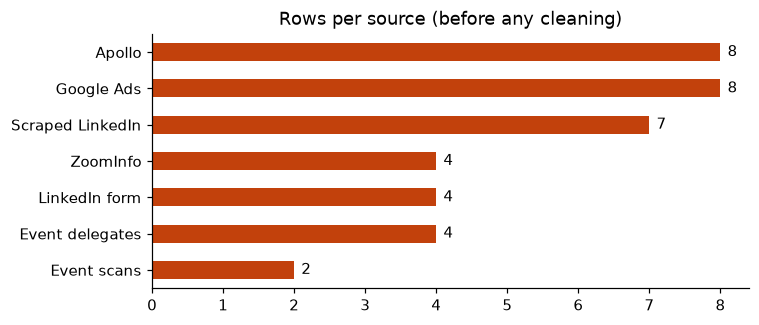

In [4]:
rows = pd.Series({name: len(df) for name, df in raw.items()})
fig, ax = plt.subplots(figsize=(7, 3))
rows.sort_values().plot.barh(ax=ax, color=ORANGE)
ax.set_title("Rows per source (before any cleaning)")
for i, v in enumerate(rows.sort_values()):
    ax.text(v + 0.1, i, str(v), va="center")
plt.show()

## 1. Map columns to one record shape

`Work email`, `Email ID`, `Email Address` and `Email` all mean the same thing. Step 1 rewrites every row into one common
`Rec` record (source, date, name, e-mails, phones, company, title, LinkedIn ids, company facts), and parses the four
different date formats into comparable timestamps. Dates matter because **the latest dated source wins** for someone's
employer and title.

In [5]:
kept, removed = load_all(DATA)
records = pd.DataFrame([dataclasses.asdict(r) for r in kept])
records[["source", "ref", "date", "full", "company", "title", "emails", "phones"]].head(10)

,source,ref,date,full,company,title,emails,phones
0,Google Ads,leads!2,2026-10-05 07:39:15,Lena Park,Kestrel Logistics Pvt Ltd,Mktg Manager,"(lena.park@kestrellogistics.com,)","((98000 10001, self),)"
1,Google Ads,leads!3,2026-10-06 03:42:00,Omar Diaz,Kestrel,Dir. Sales,"(omardiaz7731x@gmail.com,)","((09700020001, self),)"
2,Google Ads,leads!4,2026-10-07 12:10:21,Tom Baker,Lumen Retial,Head of IT,"(tom.baker@lumenretail.con,)","((NA, self),)"
3,Google Ads,leads!5,2026-10-08 04:31:44,Nina Cho,Sparrow Fintech Pte. Ltd.,Sr Mgr - Sales,"(nina.cho@sparrowfin.io; info@sparrowfin.io,)","((0000000000, self),)"
4,Google Ads,leads!6,2026-10-08 04:31:44,Nina Cho,Sparrow Fintech Pte. Ltd.,Sr Mgr - Sales,"(nina.cho@sparrowfin.io; info@sparrowfin.io,)","((0000000000, self),)"
5,Event Delegate,Delegate List!6,2026-09-19 00:00:00,Lena Park,Kestrel,Chief Rev Officer,"(lpark@kestrellogistics.com,)","((9800010002, self),)"
6,Event Delegate,Delegate List!7,2026-09-19 00:00:00,Maya Iyer,Driftwood Pay Pte. Ltd.,Growth Head,"(maya.iyer@driftwoodpay.com,)","((+6590001234, self),)"
7,Event Delegate,Delegate List!8,2026-09-19 00:00:00,Ravi Menon,,Manager - Procurement,"(ravi.menon@sparrowfin.io,)","((9.18772E+11, self),)"
8,Event Delegate,Delegate List!9,2026-09-19 00:00:00,Sam Ortiz,Harbor,Purchase Manager,"(mailto:sam.ortiz@harborsoft.com,)","((080-43057296, self),)"
9,Event Booth Scan,Booth Scans!2,2026-09-18 07:55:00,Omar Diaz,Kestrel Logistics,Director - Sales,"(mailto:omar.diaz@kestrellogistics.com,)","((, self), (9700020001, self))"


## 2. Clean and remove invalid records

Names lose salutations, credentials, pronouns and emoji; `Last, First` is flipped. Then rows that should never reach
the list are removed **with a reason**: test leads, spam, job seekers, hidden LinkedIn Members.

Note what is *not* removed: a row with a **blank company**. Another source may know the company, so that decision is
made after merging.

,source,ref,name,company,reason
0,Google Ads,leads!7,Google Test,Google Test Co,test/spam lead
1,Google Ads,leads!8,Alex Student,Student,job seeker / freelancer
2,Google Ads,leads!9,Asdf Asdf,asdf,test/spam lead
3,LinkedIn Scraped,result!7,Linkedin Member,Kestrel Logistics,hidden LinkedIn Member
4,LinkedIn Scraped,result!8,Linkedin Member,Sparrow Fintech,hidden LinkedIn Member


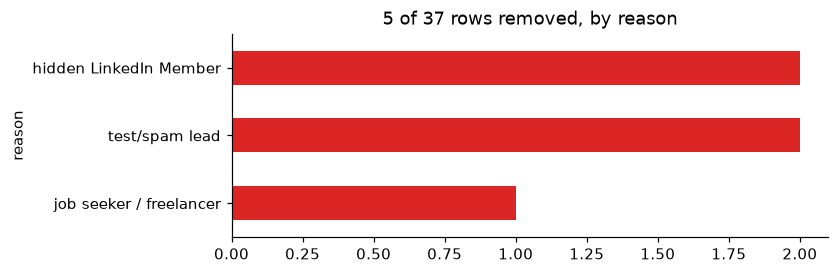

kept despite a blank company: [('Event Delegate', 'Ravi Menon')]


In [6]:
rem = pd.DataFrame([dataclasses.asdict(r) for r in removed])
display(rem[["source", "ref", "name", "company", "reason"]])

fig, ax = plt.subplots(figsize=(7, 2.4))
rem["reason"].value_counts().sort_values().plot.barh(ax=ax, color=RED)
ax.set_title(f"{len(removed)} of {len(kept) + len(removed)} rows removed, by reason")
plt.show()

blank = [r for r in kept if not r.company]
print(f"kept despite a blank company: {[(r.source, r.full) for r in blank]}")

## 3. Standardize to the Rules-tab formats

This is where the field rules become code: canonical company (typos, legal suffixes, short names), spelled-out job
titles, validated e-mails, **E.164 mobile numbers**, and city/country. The table shows raw value next to standardized
value for the rows that changed.

In [7]:
preps = prepare(kept)
std = pd.DataFrame([{
    "source": p.rec.source,
    "title (raw)": p.rec.title, "title (standard)": p.title_c,
    "company (raw)": p.rec.company, "company (standard)": p.company_c,
    "phone (raw)": ", ".join(r for r, _ in p.rec.phones if r), "mobile (E.164)": ", ".join(n for n, _ in p.phones),
    "e-mail (raw)": "; ".join(e for e in p.rec.emails if e), "e-mail (valid)": ", ".join(f"{e} [{s}]" for e, s in p.emails),
} for p in preps])
changed = std[(std["title (raw)"] != std["title (standard)"]) | (std["company (raw)"] != std["company (standard)"])
              | (std["phone (raw)"] != std["mobile (E.164)"])]
changed.head(14)

,source,title (raw),title (standard),company (raw),company (standard),phone (raw),mobile (E.164),e-mail (raw),e-mail (valid)
0,Google Ads,Mktg Manager,Marketing Manager,Kestrel Logistics Pvt Ltd,Kestrel Logistics,98000 10001,+919800010001,lena.park@kestrellogistics.com,lena.park@kestrellogistics.com [ok]
1,Google Ads,Dir. Sales,Director of Sales,Kestrel,Kestrel Logistics,09700020001,+919700020001,omardiaz7731x@gmail.com,omardiaz7731x@gmail.com [ok]
2,Google Ads,Head of IT,Head of Information Technology,Lumen Retial,Lumen Retail,NA,,tom.baker@lumenretail.con,tom.baker@lumenretail.com [repaired]
3,Google Ads,Sr Mgr - Sales,Senior Sales Manager,Sparrow Fintech Pte. Ltd.,Sparrow Fintech,0000000000,,nina.cho@sparrowfin.io; info@sparrowfin.io,nina.cho@sparrowfin.io [ok]
4,Google Ads,Sr Mgr - Sales,Senior Sales Manager,Sparrow Fintech Pte. Ltd.,Sparrow Fintech,0000000000,,nina.cho@sparrowfin.io; info@sparrowfin.io,nina.cho@sparrowfin.io [ok]
5,Event Delegate,Chief Rev Officer,Chief Revenue Officer,Kestrel,Kestrel Logistics,9800010002,+919800010002,lpark@kestrellogistics.com,lpark@kestrellogistics.com [ok]
6,Event Delegate,Growth Head,Head of Growth,Driftwood Pay Pte. Ltd.,Driftwood Pay,+6590001234,+6590001234,maya.iyer@driftwoodpay.com,maya.iyer@driftwoodpay.com [ok]
7,Event Delegate,Manager - Procurement,Procurement Manager,,,9.18772E+11,,ravi.menon@sparrowfin.io,ravi.menon@sparrowfin.io [ok]
8,Event Delegate,Purchase Manager,Procurement Manager,Harbor,Harbor Software,080-43057296,,mailto:sam.ortiz@harborsoft.com,sam.ortiz@harborsoft.com [ok]
9,Event Booth Scan,Director - Sales,Director of Sales,Kestrel Logistics,Kestrel Logistics,9700020001,+919700020001,mailto:omar.diaz@kestrellogistics.com,omar.diaz@kestrellogistics.com [ok]


### Which phone column can you trust?

The Rules say *mobile only: no board lines or direct lines*. But vendor columns are mislabeled. Rather than trust a
label, **measure it**: how many numbers in a column also appear, as the same number, in another source? A real mobile
shows up in several places; a board line shows up nowhere else.

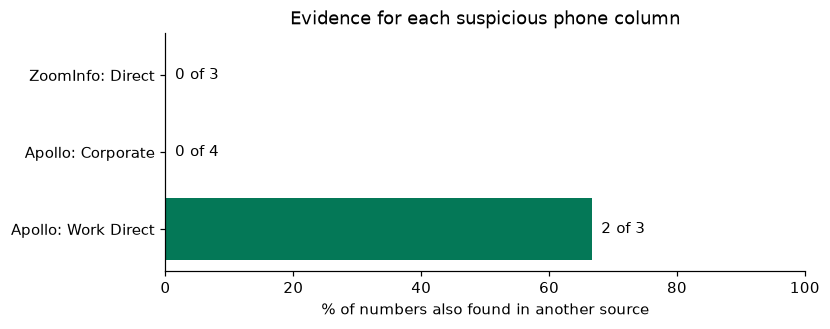

In [8]:
def key(value):
    # compare numbers by their last 8 digits, whatever the formatting (spaces, +91, 0 prefix, apostrophes)
    digits = re.sub(r"\D", "", str(value))
    return digits[-8:] if len(digits) >= 8 and len(set(digits)) > 1 else None


def keys(series):
    return {k for k in (key(v) for v in series.dropna()) if k}


apollo, zi = raw["Apollo"], raw["ZoomInfo"]
columns = {
    "Apollo: Work Direct": apollo["Work Direct Phone"], "Apollo: Corporate": apollo["Corporate Phone"],
    "ZoomInfo: Direct": zi["Direct Phone Number"],
}
# every OTHER place a person's number can appear
elsewhere = set()
for df, col in [(raw["Google Ads"], "Phone number"), (raw["Event delegates"], "Contact No"), (raw["Event scans"], "Phone"),
                (raw["LinkedIn form"], "Phone Number"), (raw["Apollo"], "Mobile Phone"), (raw["ZoomInfo"], "Mobile phone")]:
    elsewhere |= keys(df[col])
notes = raw["Event scans"]["Notes"].dropna().str.extract(r"Mob\s+(\d+)")[0].dropna()  # numbers typed into free text
elsewhere |= keys(notes)

stats = {label: (len(ks := keys(series)), len(ks & elsewhere)) for label, series in columns.items()}
share = pd.Series({k: (hit / total if total else 0) for k, (total, hit) in stats.items()})
fig, ax = plt.subplots(figsize=(7.5, 2.8))
ax.barh(share.index, share.values * 100, color=[GREEN if v > 0.4 else RED for v in share.values])
ax.set_xlim(0, 100)
ax.set_xlabel("% of numbers also found in another source")
for i, (label, (total, hit)) in enumerate(stats.items()):
    ax.text(share[label] * 100 + 1.5, i, f"{hit} of {total}", va="center")
ax.set_title("Evidence for each suspicious phone column")
plt.show()

Board lines (*Corporate*) and direct lines (*Direct*) are never corroborated, so they are excluded. *Work Direct* is
usually a mislabeled mobile, so it is accepted **only when another source agrees**. The one number that nothing
corroborates is left blank and flagged (see [ADR-0004](../../../docs/adr/0004-mobile-only-phone-policy-with-corroboration.md)).

## 4. Group records into people

Which records describe the same real person? Records are linked when they share an **e-mail, mobile number, LinkedIn
slug or Sales Navigator id**. Same name and company counts only with a *compatible title*. And one rule is absolute:
**never merge two records that carry different LinkedIn identities.**

In [9]:
clusters, links = build_clusters(preps)
people_groups = pd.DataFrame([{
    "person": Counter(p.rec.full for p in c).most_common(1)[0][0],
    "records": len(c),
    "sources": ", ".join(sorted({p.rec.source for p in c})),
    "companies": ", ".join(sorted({p.company_c for p in c if p.company_c})),
    "titles": ", ".join(sorted({p.title_c for p in c if p.title_c})),
} for c in clusters]).sort_values("records", ascending=False)
print(f"{len(preps)} records -> {len(clusters)} people")
people_groups

32 records -> 12 people


,person,records,sources,companies,titles
5,Maya Iyer,4,"Apollo, Event Delegate, LinkedIn Lead Gen Fo...","Driftwood Pay, Sparrow Fintech","Head of Growth, Vice President of Marketing"
8,Hana Weiss,4,"Apollo, Event Booth Scan, LinkedIn Scraped",Harbor Software,Revenue Operations Manager
0,Lena Park,3,"Google Ads, LinkedIn Lead Gen Form, ZoomInfo",Kestrel Logistics,Marketing Manager
1,Omar Diaz,3,"Apollo, Event Booth Scan, Google Ads",Kestrel Logistics,Director of Sales
3,Nina Cho,3,"Google Ads, ZoomInfo",Sparrow Fintech,Senior Sales Manager
4,Lena Park,3,"Apollo, Event Delegate, LinkedIn Scraped",Kestrel Logistics,Chief Revenue Officer
6,Ravi Menon,3,"Apollo, Event Delegate, ZoomInfo",Sparrow Fintech,Procurement Manager
9,Kate Doyle,3,"Apollo, LinkedIn Lead Gen Form, LinkedIn Scr...",Tidewater Health,Chief Marketing Officer
7,Sam Ortiz,2,"Apollo, Event Delegate",Harbor Software,Procurement Manager
10,Zed Quill,2,"LinkedIn Lead Gen Form, ZoomInfo",Tidewater Health,Director of Operations


In [10]:
pd.DataFrame([dataclasses.asdict(link) for link in links])[["kind", "note"]]

,kind,note
0,name+company+title,Hana Weiss @ Harbor Software (Revenue Operat...
1,name+company+title,Hana Weiss @ Harbor Software (Revenue Operat...


Every non-trivial merge is a logged decision. Now see it. Each panel is one person; nodes are the source records, solid
lines are shared strong keys (e-mail, mobile, slug, Sales Navigator id), dashed lines mean the two records are linked
indirectly: through other records of the same person, or by name + company + compatible title.

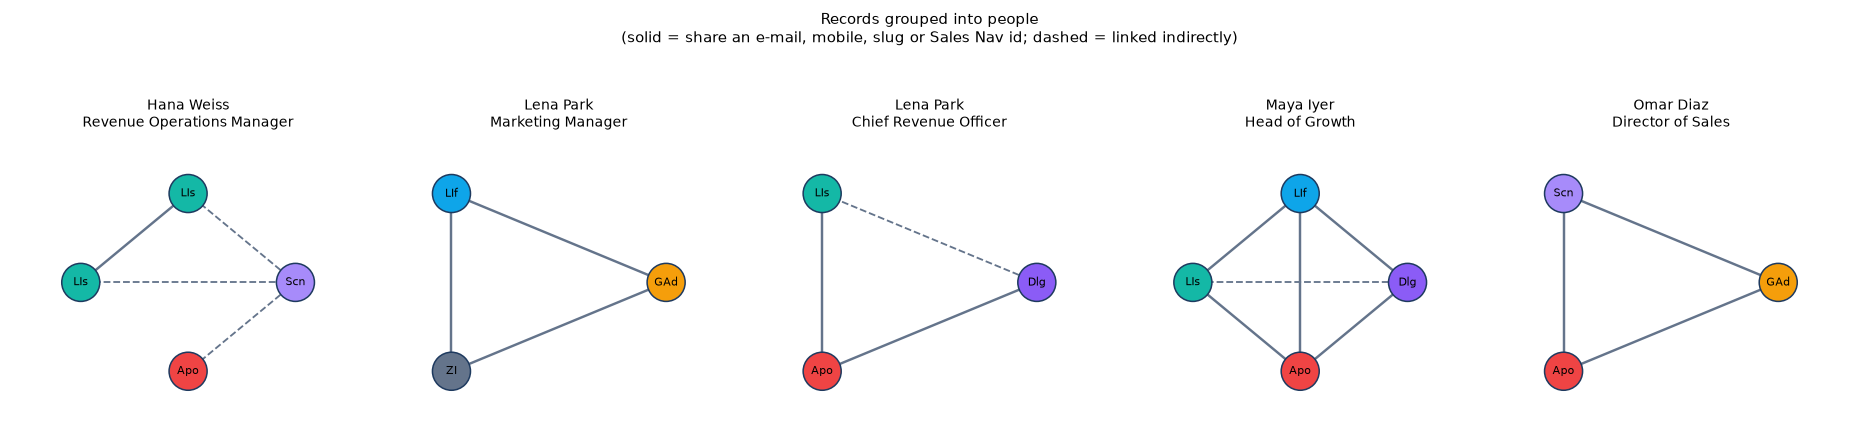

In [11]:
SHORT = {"Google Ads": "GAd", "Event Delegate": "Dlg", "Event Booth Scan": "Scn", "LinkedIn Lead Gen Form": "LIf",
         "LinkedIn Scraped": "LIs", "Apollo": "Apo", "ZoomInfo": "ZI"}
SRC_COLOR = {"Google Ads": "#f59e0b", "Event Delegate": "#8b5cf6", "Event Booth Scan": "#a78bfa",
             "LinkedIn Lead Gen Form": "#0ea5e9", "LinkedIn Scraped": "#14b8a6", "Apollo": "#ef4444", "ZoomInfo": "#64748b"}
interesting = [c for c in clusters if Counter(p.rec.full for p in c).most_common(1)[0][0] in
               ("Lena Park", "Maya Iyer", "Hana Weiss", "Omar Diaz") and len(c) > 1]
interesting.sort(key=lambda c: (Counter(p.rec.full for p in c).most_common(1)[0][0], -len(c)))
fig, axes = plt.subplots(1, len(interesting), figsize=(3.4 * len(interesting), 3.8))
for ax, c in zip(axes, interesting, strict=True):
    g = nx.Graph()
    keys = {}
    for i, p in enumerate(c):
        g.add_node(i)
        for k in _strong_keys(p):
            keys.setdefault(k, []).append(i)
    strong = {(a, b) for ids in keys.values() for a in ids for b in ids if a < b}
    weak = {(0, i) for i in range(1, len(c))} - strong
    g.add_edges_from(strong | weak)
    pos = nx.circular_layout(g)
    nx.draw_networkx_edges(g, pos, edgelist=list(strong), ax=ax, edge_color=GREY, width=1.6)
    nx.draw_networkx_edges(g, pos, edgelist=list(weak), ax=ax, edge_color=GREY, style="dashed", width=1.2)
    nx.draw_networkx_nodes(g, pos, ax=ax, node_size=620, node_color=[SRC_COLOR[p.rec.source] for p in c], edgecolors="#1e3a5f")
    nx.draw_networkx_labels(g, pos, {i: SHORT[p.rec.source] for i, p in enumerate(c)}, ax=ax, font_size=7)
    name = Counter(p.rec.full for p in c).most_common(1)[0][0]
    title = Counter(p.title_c for p in c if p.title_c).most_common(1)[0][0]
    ax.set_title(f"{name}\n{title}", fontsize=9)
    ax.axis("off")
    ax.margins(0.25)
fig.suptitle("Records grouped into people\n(solid = share an e-mail, mobile, slug or Sales Nav id; dashed = linked indirectly)",
             y=1.04, fontsize=10)
plt.tight_layout()
plt.show()

Notice the two **Lena Park** panels: same name, same company, but different titles and different LinkedIn slugs, so
they stay two people. Here is the guard that protects that, demonstrated by forcing a shared e-mail onto both:

In [12]:
lenas = [p for p in preps if p.rec.full == "Lena Park" and p.rec.slug]
shared = (("shared@example.com", "ok"),)
a = dataclasses.replace(lenas[0], emails=shared)
b = dataclasses.replace(next(p for p in lenas if p.rec.slug != a.rec.slug), emails=shared)
forced_clusters, forced_links = build_clusters([a, b])
print(f"two Lena Park records sharing an e-mail, with slugs {a.rec.slug!r} and {b.rec.slug!r}")
print(f"-> {len(forced_clusters)} people (merge refused)")
for link in forced_links:
    print("  ", link.kind, "|", link.note)

two Lena Park records sharing an e-mail, with slugs 'lena-park-1a2b3c4d' and 'lena-park-77'
-> 2 people (merge refused)
   REFUSED merge | email:shared@example.com: different LinkedIn identities


## 5. Enrich and merge: one row per person

Each group becomes one row, filling gaps from the other sources and never guessing:

- **Employer and title:** the most recent *dated* source wins.
- **Company facts** (website, HQ, size): ZoomInfo first, then Apollo, then everything else.
- **E-mail:** a work address on the *current* employer's domain beats a personal address and an old employer's address.
- **Mobile:** only trusted numbers. Unknown stays blank.

In [13]:
people, dropped = build_all(clusters, preps)
final = pd.DataFrame([p.row for p in people])[list(COLUMNS)]
final

,Company Name,Website,HQ Location,Company Size,Contact Person Name,First Name,Last Name,Designation/Job Title,LinkedIn URL,Mobile No.,Email ID
0,Harbor Software,harborsoft.com,"Dubai, United Arab Emirates",201-500,Sam Ortiz,Sam,Ortiz,Procurement Manager,https://www.linkedin.com/in/sam-ortiz-99cc88dd,+971501234567,sam.ortiz@harborsoft.com
1,Harbor Software,harborsoft.com,"Dubai, United Arab Emirates",201-500,Hana Weiss,Hana,Weiss,Revenue Operations Manager,,,hana.weiss@harborsoft.com
2,Kestrel Logistics,kestrellogistics.com,"Pune, India",201-500,Omar Diaz,Omar,Diaz,Director of Sales,,+919700020001,omar.diaz@kestrellogistics.com
3,Kestrel Logistics,kestrellogistics.com,"Pune, India",201-500,Lena Park,Lena,Park,Marketing Manager,https://www.linkedin.com/in/lena-park-1a2b3c4d,+919800010001,lena.park@kestrellogistics.com
4,Kestrel Logistics,kestrellogistics.com,"Pune, India",201-500,Lena Park,Lena,Park,Chief Revenue Officer,https://www.linkedin.com/in/lena-park-77,+919800010002,lpark@kestrellogistics.com
5,Lumen Retail,lumenretail.com,"London, United Kingdom",51-200,Tom Baker,Tom,Baker,Head of Information Technology,,,tom.baker@lumenretail.com
6,Lumen Retail,lumenretail.com,"London, United Kingdom",51-200,Sam Ortiz,Sam,Ortiz,Director of Marketing,https://www.linkedin.com/in/sam-ortiz-11aa22bb,+447700900123,sam.ortiz@lumenretail.com
7,Sparrow Fintech,sparrowfin.io,"Singapore, Singapore",201-500,Nina Cho,Nina,Cho,Senior Sales Manager,https://www.linkedin.com/in/nina-cho-2d3e4f5a,+6581234567,nina.cho@sparrowfin.io
8,Sparrow Fintech,sparrowfin.io,"Singapore, Singapore",201-500,Maya Iyer,Maya,Iyer,Vice President of Marketing,https://www.linkedin.com/in/maya-iyer-5e6f7a8b,+6590001234,maya.iyer@sparrowfin.io
9,Sparrow Fintech,sparrowfin.io,"Singapore, Singapore",201-500,Ravi Menon,Ravi,Menon,Procurement Manager,https://www.linkedin.com/in/ravi-menon-9a8b7c6d,,ravi.menon@sparrowfin.io


### A job changer: the latest dated record decides

Maya Iyer appears with *two* employers across the sources. The chart plots every record by date: older records (Apollo,
the event) say Driftwood Pay; the newest (LinkedIn form, scraper) say Sparrow Fintech. The latest wins, and her e-mail
switches to the new employer's domain.

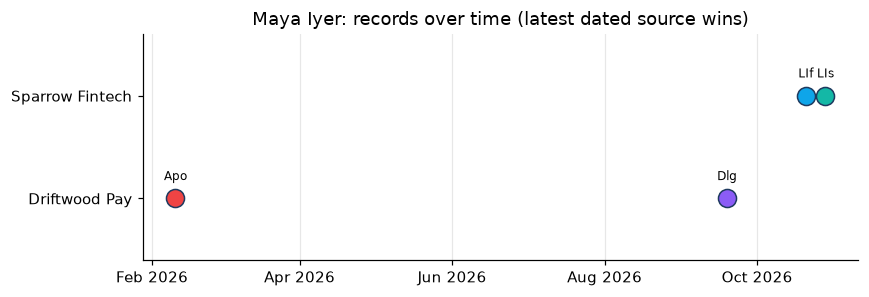

{'Company Name': 'Sparrow Fintech', 'Designation/Job Title': 'Vice President of Marketing', 'Email ID': 'maya.iyer@sparrowfin.io', 'Mobile No.': '+6590001234'}


In [14]:
maya = next(c for c in clusters if any(p.rec.full == "Maya Iyer" for p in c))
dated = [(p.rec.date, p.company_c, p.rec.source) for p in maya if p.rec.date]
companies = sorted({c for _, c, _ in dated})
fig, ax = plt.subplots(figsize=(8, 2.8))
for when, company, source in dated:
    ax.scatter(when, companies.index(company), s=140, color=SRC_COLOR[source], edgecolor="#1e3a5f", zorder=3)
    ax.annotate(SHORT[source], (when, companies.index(company)), textcoords="offset points", xytext=(0, 12),
                ha="center", fontsize=8)
ax.set_yticks(range(len(companies)))
ax.set_yticklabels(companies)
ax.set_ylim(-0.6, len(companies) - 0.4)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.grid(axis="x", alpha=0.3)
ax.set_title("Maya Iyer: records over time (latest dated source wins)")
plt.tight_layout()
plt.show()
person = next(p for p in people if p.row["Contact Person Name"] == "Maya Iyer")
print({k: person.row[k] for k in ("Company Name", "Designation/Job Title", "Email ID", "Mobile No.")})

### Nothing is merged without a trace

Every output row keeps the exact source rows it came from and any judgment call as a **review flag**. A human reviews
the short flag list instead of re-checking every row.

In [15]:
print("Maya's row was built from:")
for ref in person.refs:
    print("  -", ref)

flags = pd.DataFrame([{"person": p.row["Contact Person Name"], "company": p.row["Company Name"], "flag": f}
                      for p in people for f in p.flags])
flags[~flags["flag"].str.startswith(("no mobile", "no public"))].reset_index(drop=True)

Maya's row was built from:
  - Event Delegate: Delegate List!7
  - LinkedIn Lead Gen Form: leads!3
  - LinkedIn Scraped: result!3
  - Apollo: apollo-contacts-export!4


,person,company,flag
0,Tom Baker,Lumen Retail,email typo repaired to tom.baker@lumenretail...
1,Maya Iyer,Sparrow Fintech,employer changed across sources: latest date...
2,Ravi Menon,Sparrow Fintech,+6591234567 only in Apollo 'Work Direct Phon...
3,Zed Quill,Tidewater Health,personal email used: no work email in any so...


## 6. Verify

Two independent checks that the result is right.

**Against the golden file.** The committed `expected-output/Final_Contact_List.xlsx` is the reviewed result. This
notebook's output must match it cell for cell:

identical to the golden file: True (12 rows x 11 columns)


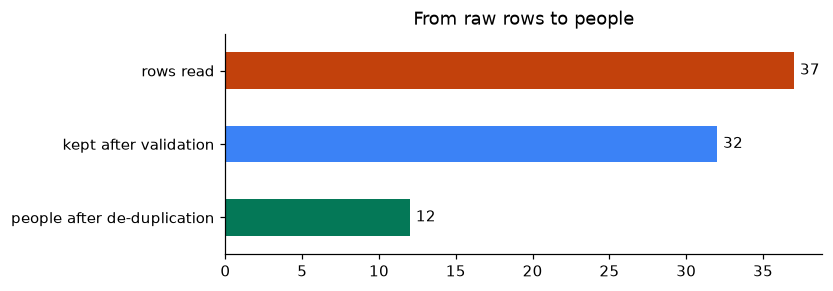

In [16]:
golden = pd.read_excel(ROOT / "expected-output" / "Final_Contact_List.xlsx", dtype=str).fillna("")
produced = final.astype(str).fillna("")
same = golden.values.tolist() == produced.values.tolist()
print("identical to the golden file:", same, f"({len(golden)} rows x {len(golden.columns)} columns)")
assert same

total = len(kept) + len(removed)
stages = pd.Series({"rows read": total, "kept after validation": len(kept), "people after de-duplication": len(people)})
fig, ax = plt.subplots(figsize=(7, 2.6))
stages[::-1].plot.barh(ax=ax, color=[GREEN, BLUE, ORANGE])
for i, v in enumerate(stages[::-1]):
    ax.text(v + 0.4, i, str(v), va="center")
ax.set_title("From raw rows to people")
plt.show()

**Against the n8n workflow.** The same rules are implemented a second time as JavaScript inside n8n Code nodes. The
parity check runs that JavaScript on this same data under Node and requires every cell to match the Python result.
(Skipped automatically if Node is not installed.)

In [17]:
if shutil.which("node"):
    run = subprocess.run([sys.executable, str(ROOT / "scripts" / "parity_check.py")], capture_output=True, text=True, cwd=ROOT)
    print(run.stdout.strip() or run.stderr.strip())
    assert run.returncode == 0, "n8n JavaScript and the Python reference disagree"
else:
    print("node not found: skipping the JS parity check (install Node 20+ to run it)")

mapped=37 removed=5 kept=32 people=12
golden rows=12 js rows=12 differing rows=0


## Try it yourself

1. **Break a rule on purpose.** In `pipeline/normalize.py`, lower the company-match threshold from `0.86` and rerun
   section 3. Which typo'd company names now match the wrong company?
2. **Add a hard case.** Edit `scripts/make_sample_data.py` to add a person who changed employers *twice*, regenerate
   the sample, and check how section 5 decides.
3. **Change who wins.** Make Apollo outrank ZoomInfo for company size in `pipeline/build.py` and watch which rows
   change in the final table (and which tests fail).

Where to go next: [algorithms](../docs/algorithms.md) · [rules traceability](../docs/rules-traceability.md) ·
[decision records](../../../docs/adr/README.md) · [the n8n workflow](../workflow/contact-list-merge.workflow.json).